In [49]:
import pandas as pd
import numpy as np
%matplotlib inline

# Required for basic python plotting functionality
import matplotlib.pyplot as plt
# Required for formatting dates later in the case
import matplotlib.dates as mdates
# Required to display image inline
from IPython.display import Image
# Advanced plotting functionality with seaborn
import seaborn as sns
import sklearn.metrics       as Metrics
import folium  #needed for interactive map
from folium.plugins import HeatMap
from   collections           import Counter
from   sklearn               import preprocessing
from   datetime              import datetime
from   collections           import Counter
from   math                  import exp
from   sklearn.linear_model  import LinearRegression as LinReg
from   sklearn.metrics       import mean_absolute_error
from   sklearn.metrics       import median_absolute_error
from   sklearn.metrics       import r2_score
import base64
import datetime
import json
import os
from geopy.geocoders import Nominatim
import statsmodels.api as sm
from statsmodels.formula.api import ols
import statsmodels
from scipy import stats 
from scipy.stats import ttest_ind
from pingouin import pairwise_tests #this is for performing the pairwise tests
from pingouin import pairwise_ttests #this is for performing the pairwise tests
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
from scipy.stats import chi2
import nltk # imports the natural language toolkit
nltk.download('punkt')
nltk.download('stopwords')
import string
import plotly
from nltk.stem import PorterStemmer 
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

import statsmodels.formula.api as sm
import statsmodels.formula.api as smf
import statsmodels.api         as sm
import scipy
plt.style.use('ggplot')
from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()

Extracting all the data from the dataset.csv file in a df dataframe.

In [50]:
df = pd.read_csv("dataset.csv")
df

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,...,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music
113996,113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,...,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music
113997,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,...,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music
113998,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,...,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music


### Data Cleaning and Pre-processing:

In this step, we identified that there is one missing or null value in our dataset for columns artist, album_name, and track_name. Since these fields are critical and cannot be reasonably identified or approximated, and hence we will drop the rows containing the missing values in these columns. 

To enhance efficiency and avoid redundancy, we will also remove any duplicate rows present in our dataset. All these steps will help ensure that our dataset upon which we will be working on, is clean, reliable and ready.


In [51]:
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

For tracks in filtered_df, where all the attributes are same except their genre, we are going to combine them into single row so that we can work upon it more efficiently. This will allow us to keep the track information while accounting for multiple genre associated with the same track, thus improving the dataset efficiency and usability for further analysis.

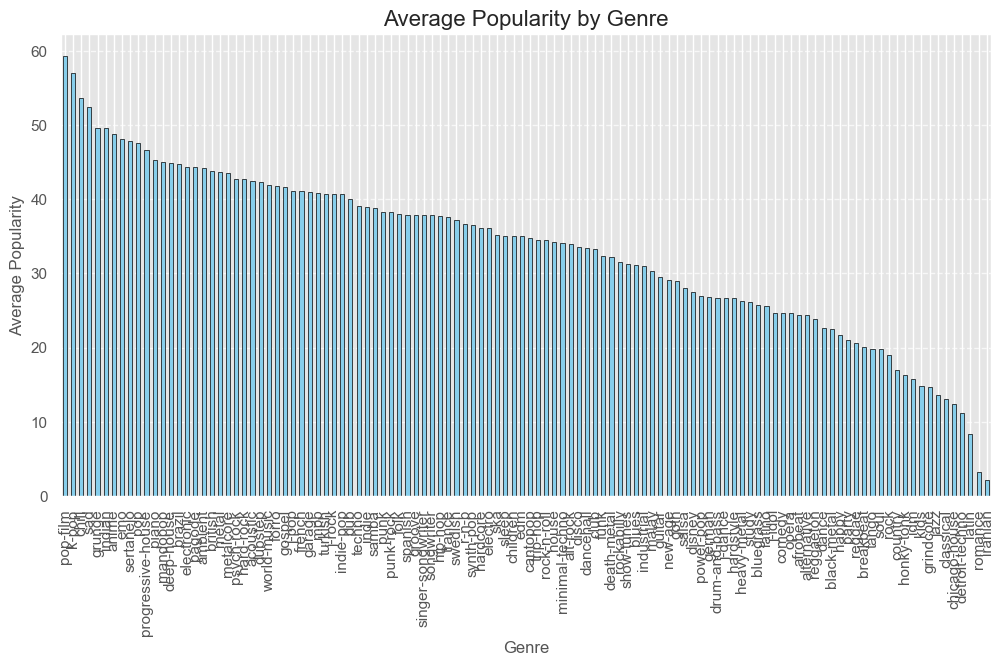

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_minutes
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,"acoustic, j-pop, singer-songwriter, songwriter",3.844433
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,"acoustic, chill",2.493500
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic,3.513767
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic,3.365550
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic,3.314217
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,...,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music,6.416650
113996,113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,...,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music,6.416667
113997,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,...,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music,4.524433
113998,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,...,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music,4.731550


In [52]:
# Here we will Remove duplicate rows and drop any na/missing values found in our dataset
df = df.dropna()
df = df.drop_duplicates()


# # Convert 'popularity' to numeric and coerce errors
df['popularity'] = pd.to_numeric(df['popularity'], errors='coerce')

# Fill missing values in non-critical columns with default values
df = df.fillna({'track_genre': 'Not-Classified'})

# Group by genre and calculate the average popularity
genre_popularity = df.groupby('track_genre')['popularity'].mean().sort_values(ascending=False)

# Plotting the average popularity for each genre
plt.figure(figsize=(12, 6))
genre_popularity.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Average Popularity by Genre', fontsize=16)
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Average Popularity', fontsize=12)
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


# Striping whitespace from string columns
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

# Converting the duration_ms to miniutes as per the spotify preference
df['duration_minutes'] = df['duration_ms'] / 60000
# Clean the dataset

# Combining genres for duplicate tracks into a single entry
df['track_genre'] = df.groupby(['track_id'])['track_genre'].transform(
    lambda x: ', '.join(sorted(set(x))))

df = df.drop_duplicates(subset=['track_id'])
df

Null Hypothesis (H₀):
It represents the average popularity of other tracks in the albums with highly popular tracks which is not higher than the average popularity of tracks in albums without highly popular tracks.
Formula: H0 :μ1 ≤μ2
​


Alternative Hypothesis (H₁):
It represents the average popularity of other tracks in the albums with highly popular tracks which is higher than the average popularity of tracks in albums without highly popular tracks.
Formula: H1:𝜇1 > 𝜇2



where:
𝜇1 is the mean popularity of tracks on albums with highly popular tracks.

𝜇2 is the mean popularity of tracks on albums without highly popular tracks.

Interpretation of Results:
If the p-value is less than the significance level (commonly 0.05):
Reject the null hypothesis. This shows us that there is enough evidence to support our claim that the average popularity of other tracks in albums with highly popular tracks is higher than in albums without such tracks.

If the p-value is greater than the significance level (commonly 0.05):
Fail to reject the null hypothesis. This shows us that there is not enough evidence to support the claim that the average popularity of other tracks in albums with highly popular tracks is higher than in albums without such tracks.

In [53]:

# Filter out albums with only one song
data_filtered = df.groupby('album_name').filter(lambda x: len(x) > 1)
data_filtered = data_filtered.drop('Unnamed: 0', axis=1)
# Define the threshold for a highly popular track (e.g., 80th percentile)
high_popularity_threshold = data_filtered['popularity'].quantile(0.8)
print(high_popularity_threshold)
# Mark albums with highly popular tracks
data_filtered['has_highly_popular_track'] = data_filtered.groupby('album_name')['popularity'].transform(lambda x: (x > high_popularity_threshold))

# Separate albums into two groups

albums_with_high_popular = data_filtered[data_filtered['has_highly_popular_track']]
albums_with_high_popular

all_tracks_from_high_popularity_albums = data_filtered[data_filtered['album_name'].isin(albums_with_high_popular['album_name'])]
all_tracks_from_high_popularity_albums = all_tracks_from_high_popularity_albums[all_tracks_from_high_popularity_albums['popularity']<49.0] 
sorted_df1 = all_tracks_from_high_popularity_albums.sort_values(by='album_name', ascending=True)
sorted_df1 = sorted_df1.groupby('album_name')['popularity'].mean()
sorted_df1 = sorted_df1.reset_index()
final_mean1  = sorted_df1['popularity'].mean()
final_mean1

all_tracks_without_high_popularity_albums = data_filtered[~data_filtered['album_name'].isin(albums_with_high_popular['album_name'])]
sorted_df2 = all_tracks_without_high_popularity_albums.sort_values(by='album_name', ascending=True)
sorted_df2 = sorted_df2.groupby('album_name')['popularity'].mean()
sorted_df2 = sorted_df2.reset_index()
final_mean2  = sorted_df2['popularity'].mean()
final_mean2

t_stat, p_value = ttest_ind(sorted_df1['popularity'], sorted_df2['popularity'], alternative='greater')
print(f"T-statistic: {t_stat}")
print(f"P-value: {p_value}")

alpha = 0.05  # Significance level
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")


49.0
T-statistic: 41.03337542759201
P-value: 0.0
Reject the null hypothesis


Here, we are going to compare the popularity between albums with highly popular tracks and albums without highly popular tracks. 
After looking at the graph, we can see that the album with highly popular tracks are more popular than album without highly popular tracks in them. 

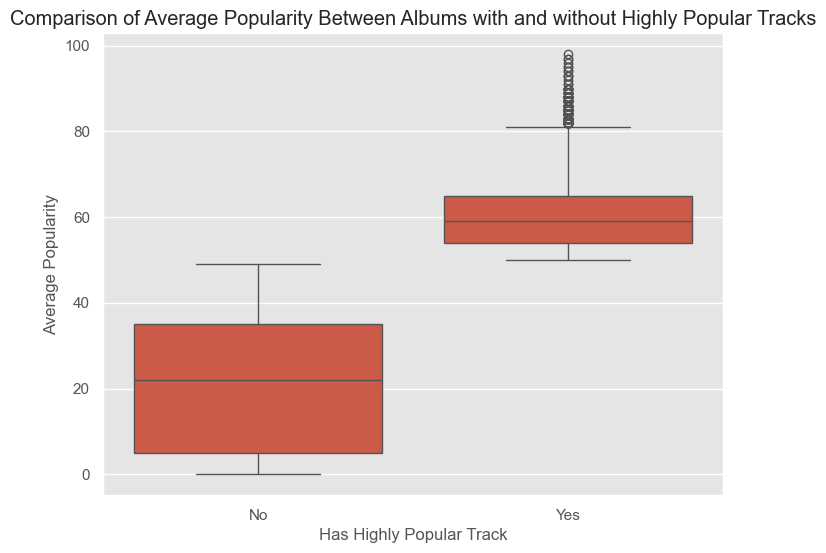

In [54]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='has_highly_popular_track', y='popularity', data=data_filtered)
plt.title('Comparison of Average Popularity Between Albums with and without Highly Popular Tracks')
plt.xlabel('Has Highly Popular Track')
plt.ylabel('Average Popularity')
plt.xticks([0, 1], ['No', 'Yes'])
plt.show()

<Figure size 800x600 with 0 Axes>

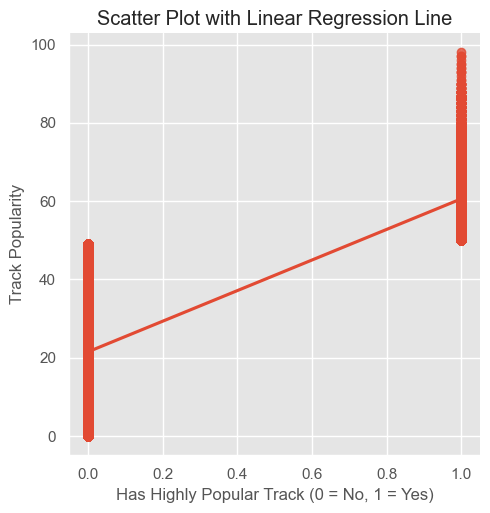

In [55]:
plt.figure(figsize=(8, 6))
sns.lmplot(x='has_highly_popular_track', y='popularity', data=data_filtered, logistic=False, ci=None)
plt.title('Scatter Plot with Linear Regression Line')
plt.xlabel('Has Highly Popular Track (0 = No, 1 = Yes)')
plt.ylabel('Track Popularity')
plt.show()

In [56]:
data_filtered

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_minutes,has_highly_popular_track
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.443,2,...,0.0526,0.469,0.000000,0.0829,0.1670,119.949,4,acoustic,3.314217,True
6,6Vc5wAMmXdKIAM7WUoEb7N,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,229400,False,0.407,0.147,2,...,0.0355,0.857,0.000003,0.0913,0.0765,141.284,3,"acoustic, piano",3.823333,True
7,1EzrEOXmMH3G43AXT1y7pA,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,242946,False,0.703,0.444,11,...,0.0417,0.559,0.000000,0.0973,0.7120,150.960,4,"acoustic, rock",4.049100,True
8,0IktbUcnAGrvD03AWnz3Q8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,189613,False,0.625,0.414,0,...,0.0369,0.294,0.000000,0.1510,0.6690,130.088,4,acoustic,3.160217,True
10,4mzP5mHkRvGxdhdGdAH7EJ,Zack Tabudlo,Episode,Give Me Your Forever,74,244800,False,0.627,0.363,8,...,0.0291,0.279,0.000000,0.0928,0.3010,99.905,4,acoustic,4.080000,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.235,5,...,0.0422,0.640,0.928000,0.0863,0.0339,125.995,5,world-music,6.416650,False
113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.117,0,...,0.0401,0.994,0.976000,0.1050,0.0350,85.239,4,world-music,6.416667,False
113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.329,0,...,0.0420,0.867,0.000000,0.0839,0.7430,132.378,4,world-music,4.524433,False
113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.506,7,...,0.0297,0.381,0.000000,0.2700,0.4130,135.960,4,world-music,4.731550,False


---

***RESEARCH QUESTION 2***

In this code, we are further categorizing our dataframe named data_filtered into two groups: solo track df and collaborative tracks df based on the artists column. We created a new column named is_collaborative and assigned boolean value such that it is considered True if its collaborative and False if its not. 

We separated two df's : solo_track_df and collab_df on basis of is_collaborative values. 

In [57]:
data_filtered['is_collaborative'] = data_filtered['artists'].apply(lambda x: ';' in str(x) or ',' in str(x) or '&' in str(x) or 'and' in str(x))
solo_tracks = data_filtered[data_filtered['is_collaborative'] == False].copy()
collaborative_tracks = data_filtered[data_filtered['is_collaborative'] == True].copy()
solo_tracks

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_minutes,has_highly_popular_track,is_collaborative
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.443,2,...,0.469,0.000,0.0829,0.1670,119.949,4,acoustic,3.314217,True,False
7,1EzrEOXmMH3G43AXT1y7pA,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,242946,False,0.703,0.444,11,...,0.559,0.000,0.0973,0.7120,150.960,4,"acoustic, rock",4.049100,True,False
10,4mzP5mHkRvGxdhdGdAH7EJ,Zack Tabudlo,Episode,Give Me Your Forever,74,244800,False,0.627,0.363,8,...,0.279,0.000,0.0928,0.3010,99.905,4,acoustic,4.080000,True,False
11,5ivF4eQBqJiVL5IAE9jRyl,Jason Mraz,Love Is a Four Letter Word,I Won't Give Up,69,240165,False,0.483,0.303,4,...,0.694,0.000,0.1150,0.1390,133.406,3,acoustic,4.002750,True,False
12,4ptDJbJl35d7gQfeNteBwp,Dan Berk,Solo,Solo,52,198712,False,0.489,0.314,7,...,0.749,0.000,0.1130,0.6070,124.234,4,"acoustic, chill",3.311867,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.235,5,...,0.640,0.928,0.0863,0.0339,125.995,5,world-music,6.416650,False,False
113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.117,0,...,0.994,0.976,0.1050,0.0350,85.239,4,world-music,6.416667,False,False
113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.329,0,...,0.867,0.000,0.0839,0.7430,132.378,4,world-music,4.524433,False,False
113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.506,7,...,0.381,0.000,0.2700,0.4130,135.960,4,world-music,4.731550,False,False


In [58]:
collaborative_tracks

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_minutes,has_highly_popular_track,is_collaborative
6,6Vc5wAMmXdKIAM7WUoEb7N,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,229400,False,0.407,0.147,2,...,0.85700,0.000003,0.0913,0.0765,141.284,3,"acoustic, piano",3.823333,True,True
8,0IktbUcnAGrvD03AWnz3Q8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,189613,False,0.625,0.414,0,...,0.29400,0.000000,0.1510,0.6690,130.088,4,acoustic,3.160217,True,True
18,2qLMf6TuEC3ruGJg4SMMN6,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,68,189613,False,0.625,0.414,0,...,0.29400,0.000000,0.1510,0.6690,130.088,4,acoustic,3.160217,True,True
19,6CgNoAbFJ4Q4Id4EjtbXlC,Boyce Avenue;Bea Miller,"Cover Sessions, Vol. 4",Photograph,67,260186,False,0.717,0.320,3,...,0.83000,0.000000,0.1070,0.3220,107.946,4,acoustic,4.336433,True,True
21,210JCw2LbYD4YIs8GiZ9iP,Boyce Avenue;Jennel Garcia,"Cover Sessions, Vol. 3",Demons,63,174174,False,0.678,0.351,0,...,0.74700,0.000000,0.3550,0.5690,90.032,4,acoustic,2.902900,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113966,42bdU7oDyRvyRXaKbUrtfu,Bethel Music;Bethany Wohrle,Victory (Live),Victory Is Yours - Live,44,333080,False,0.418,0.786,9,...,0.01050,0.000000,0.3420,0.0656,139.920,4,world-music,5.551333,False,True
113967,1eZYPovTvmxk3QlVD2VpCX,Bethel Music;Brian Johnson,We Will Not Be Shaken (Live),We Will Not Be Shaken - Live,46,332604,False,0.392,0.668,9,...,0.00356,0.000560,0.5880,0.1150,148.013,4,world-music,5.543400,False,True
113969,7mD7yAQm4GcifSnWqJdZHi,Bethel Music;Molly Skaggs,Victory (Live),Ain’t No Grave - Live,47,493293,False,0.370,0.831,4,...,0.01290,0.000122,0.1090,0.1850,148.008,4,world-music,8.221550,False,True
113975,2yAo8cJDVoMjBMS5MgrO8P,Hillsong Worship;Hillsong Young & Free,OPEN HEAVEN / River Wild,This Is Living,38,214647,False,0.611,0.857,0,...,0.00182,0.000000,0.3260,0.4640,128.001,4,world-music,3.577450,False,True


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 56470 entries, 4 to 113999
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  56470 non-null  object 
 1   artists                   56470 non-null  object 
 2   album_name                56470 non-null  object 
 3   track_name                56470 non-null  object 
 4   popularity                56470 non-null  int64  
 5   duration_ms               56470 non-null  int64  
 6   explicit                  56470 non-null  bool   
 7   danceability              56470 non-null  float64
 8   energy                    56470 non-null  float64
 9   key                       56470 non-null  int64  
 10  loudness                  56470 non-null  float64
 11  mode                      56470 non-null  int64  
 12  speechiness               56470 non-null  float64
 13  acousticness              56470 non-null  fl

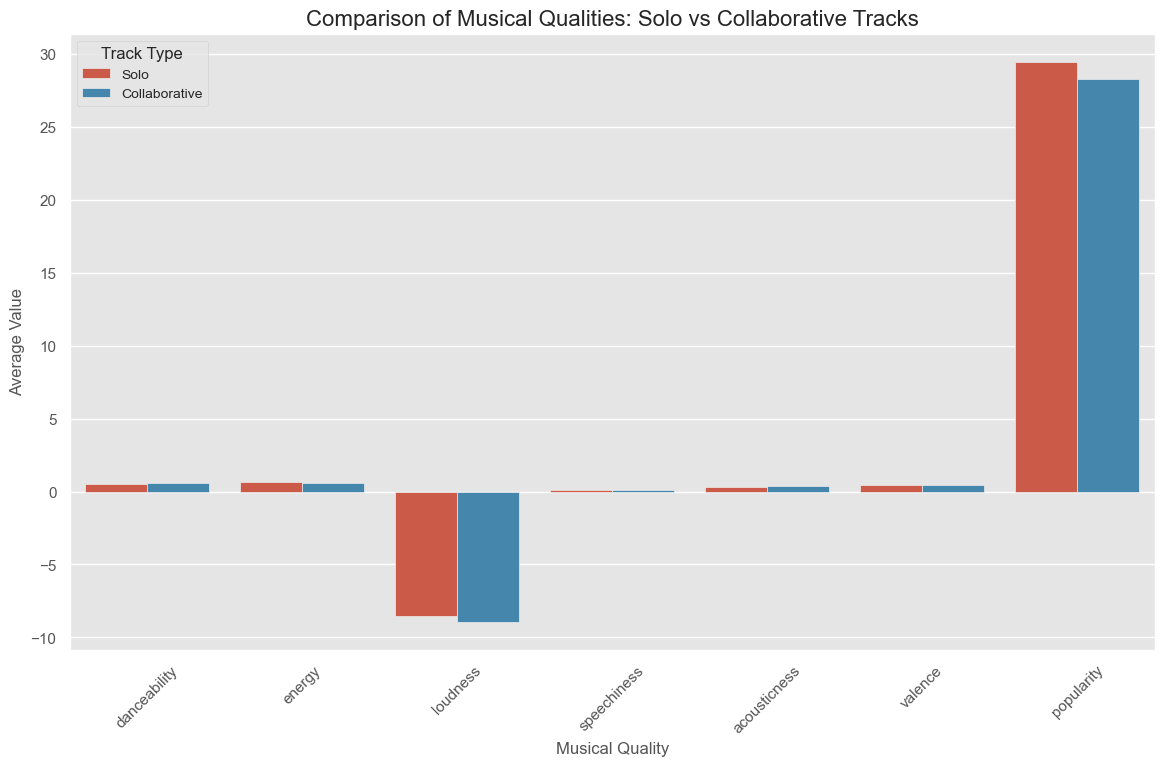

In [59]:
data = data_filtered.copy()
print("Dataset Information:")
data.info()
print("\nSolo Tracks Overview:")
print(solo_tracks.describe())
print("\nCollaborative Tracks Overview:")
print(collaborative_tracks.describe())

melted_data = data.copy()
melted_data['type'] = melted_data['is_collaborative'].replace({True: 'Collaborative', False: 'Solo'})
melted_data = melted_data.melt(id_vars=['type'], 
                               value_vars=['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'valence', 'popularity'],
                               var_name='Attribute', value_name='Value')

plt.figure(figsize=(14, 8))
sns.barplot(data=melted_data, x='Attribute', y='Value', hue='type', ci=None)
plt.title('Comparison of Musical Qualities: Solo vs Collaborative Tracks', fontsize=16)
plt.ylabel('Average Value', fontsize=12)
plt.xlabel('Musical Quality', fontsize=12)
plt.legend(title='Track Type', fontsize=10)
plt.xticks(rotation=45)
plt.show()

In [60]:
collaborative_tracks

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_minutes,has_highly_popular_track,is_collaborative
6,6Vc5wAMmXdKIAM7WUoEb7N,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,229400,False,0.407,0.147,2,...,0.85700,0.000003,0.0913,0.0765,141.284,3,"acoustic, piano",3.823333,True,True
8,0IktbUcnAGrvD03AWnz3Q8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,189613,False,0.625,0.414,0,...,0.29400,0.000000,0.1510,0.6690,130.088,4,acoustic,3.160217,True,True
18,2qLMf6TuEC3ruGJg4SMMN6,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,68,189613,False,0.625,0.414,0,...,0.29400,0.000000,0.1510,0.6690,130.088,4,acoustic,3.160217,True,True
19,6CgNoAbFJ4Q4Id4EjtbXlC,Boyce Avenue;Bea Miller,"Cover Sessions, Vol. 4",Photograph,67,260186,False,0.717,0.320,3,...,0.83000,0.000000,0.1070,0.3220,107.946,4,acoustic,4.336433,True,True
21,210JCw2LbYD4YIs8GiZ9iP,Boyce Avenue;Jennel Garcia,"Cover Sessions, Vol. 3",Demons,63,174174,False,0.678,0.351,0,...,0.74700,0.000000,0.3550,0.5690,90.032,4,acoustic,2.902900,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113966,42bdU7oDyRvyRXaKbUrtfu,Bethel Music;Bethany Wohrle,Victory (Live),Victory Is Yours - Live,44,333080,False,0.418,0.786,9,...,0.01050,0.000000,0.3420,0.0656,139.920,4,world-music,5.551333,False,True
113967,1eZYPovTvmxk3QlVD2VpCX,Bethel Music;Brian Johnson,We Will Not Be Shaken (Live),We Will Not Be Shaken - Live,46,332604,False,0.392,0.668,9,...,0.00356,0.000560,0.5880,0.1150,148.013,4,world-music,5.543400,False,True
113969,7mD7yAQm4GcifSnWqJdZHi,Bethel Music;Molly Skaggs,Victory (Live),Ain’t No Grave - Live,47,493293,False,0.370,0.831,4,...,0.01290,0.000122,0.1090,0.1850,148.008,4,world-music,8.221550,False,True
113975,2yAo8cJDVoMjBMS5MgrO8P,Hillsong Worship;Hillsong Young & Free,OPEN HEAVEN / River Wild,This Is Living,38,214647,False,0.611,0.857,0,...,0.00182,0.000000,0.3260,0.4640,128.001,4,world-music,3.577450,False,True


In [61]:

summary_stats = data_filtered.groupby('is_collaborative')[['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'valence', 'popularity']].mean().reset_index()
summary_stats['type'] = summary_stats['is_collaborative'].replace({True: 'Collaborative', False: 'Solo'})
summary_stats = summary_stats.drop(columns=['is_collaborative'])
print("\nSummary Statistics:\n", summary_stats)



Summary Statistics:
    danceability    energy  loudness  speechiness  acousticness   valence  \
0      0.541096  0.641273 -8.509934     0.088529      0.325898  0.470724   
1      0.574198  0.600729 -8.921938     0.085345      0.363717  0.465211   

   popularity           type  
0   29.483461           Solo  
1   28.282129  Collaborative  


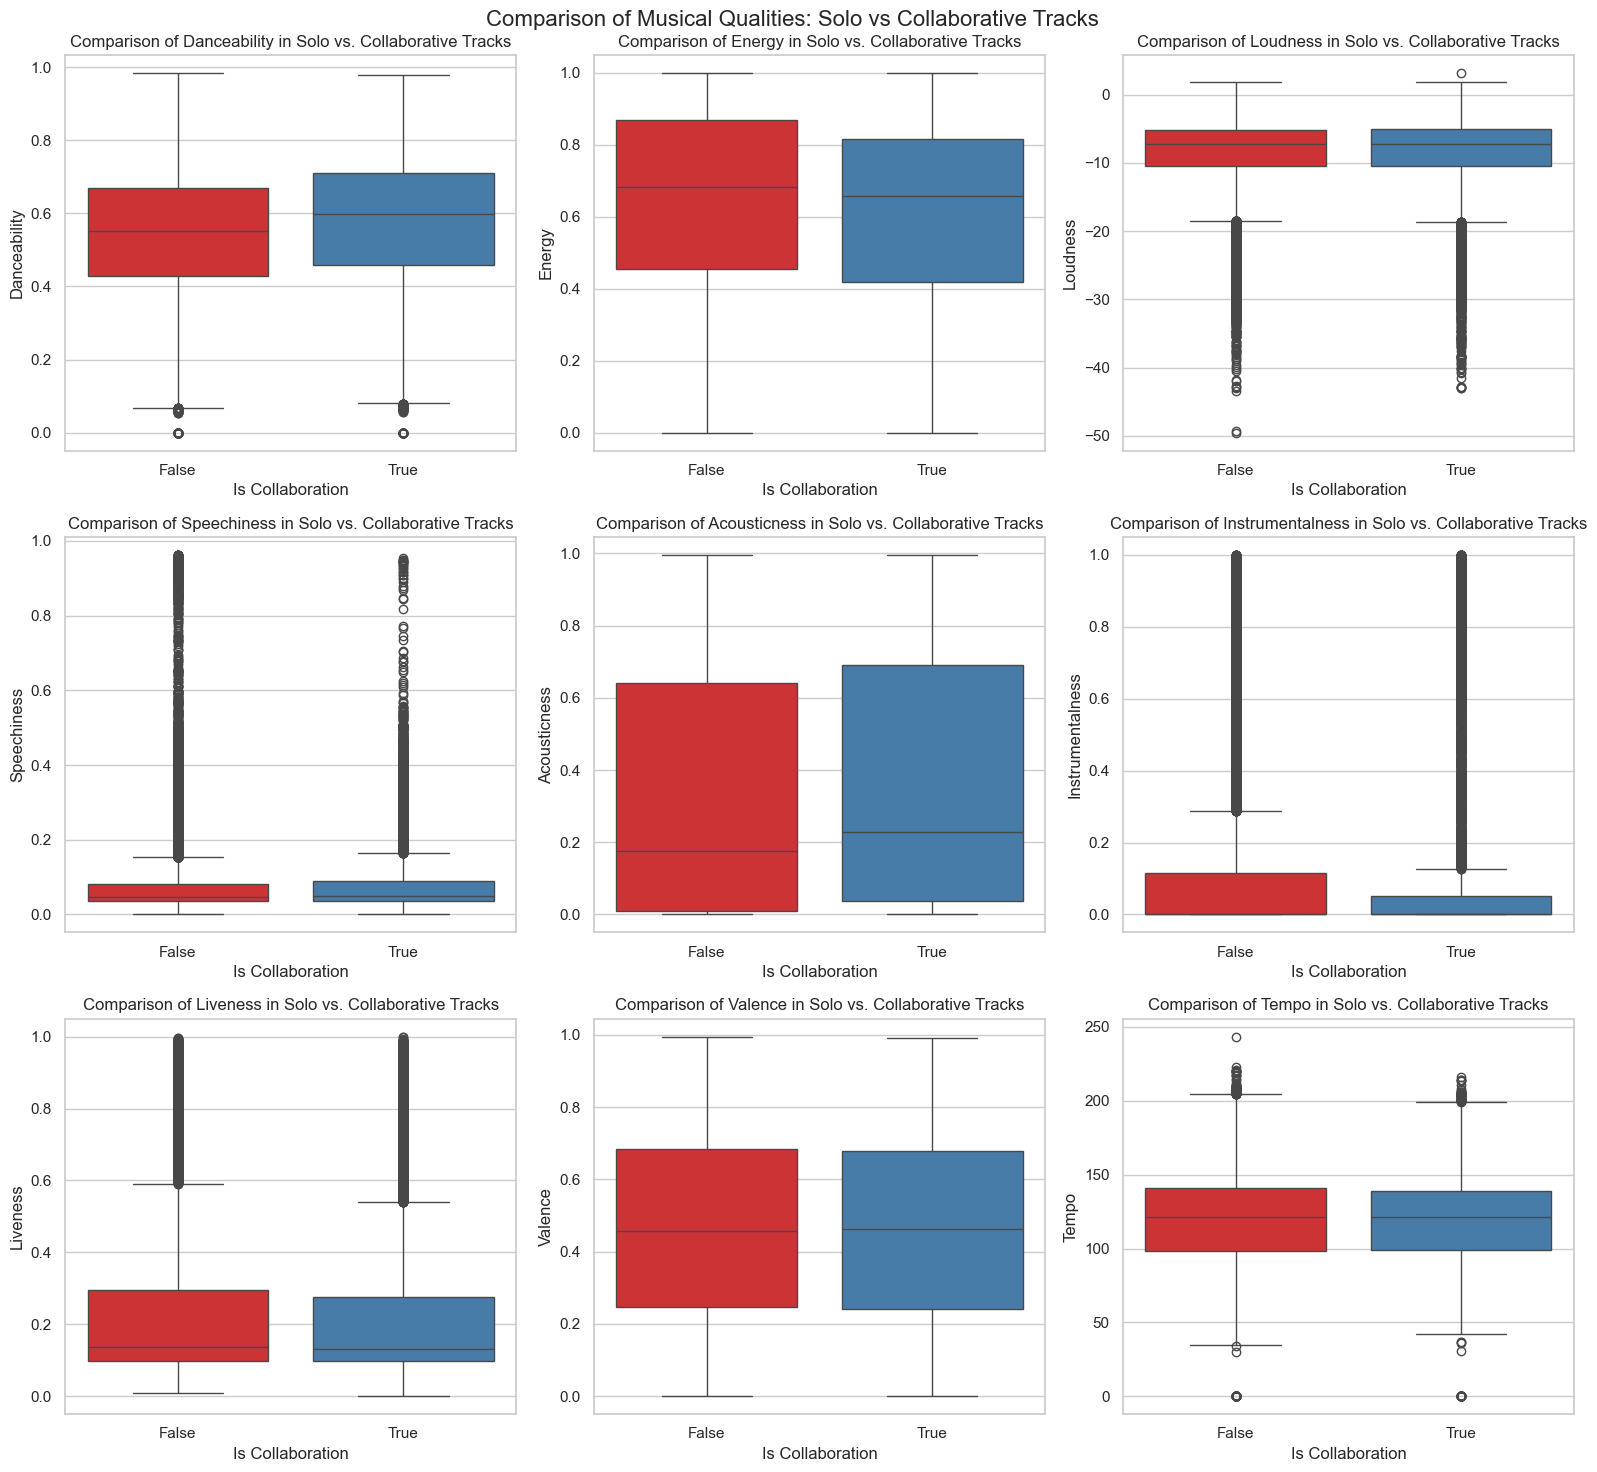

In [62]:
sns.set(style="whitegrid")


musical_qualities = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

rows = (len(musical_qualities) + 2) // 3 
cols = 3


fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 5))
fig.suptitle('Comparison of Musical Qualities: Solo vs Collaborative Tracks', fontsize=16)

axes = axes.flatten()

# Graph for each of the musical qualities.
for i, quality in enumerate(musical_qualities):
    sns.boxplot(data=data, x='is_collaborative', y=quality, ax=axes[i], palette="Set1", legend=False, hue='is_collaborative')
    axes[i].set_title(f'Comparison of {quality.capitalize()} in Solo vs. Collaborative Tracks')
    axes[i].set_xlabel('Is Collaboration')
    axes[i].set_ylabel(quality.capitalize())

# Hiding any unused axes
for j in range(len(musical_qualities), len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()



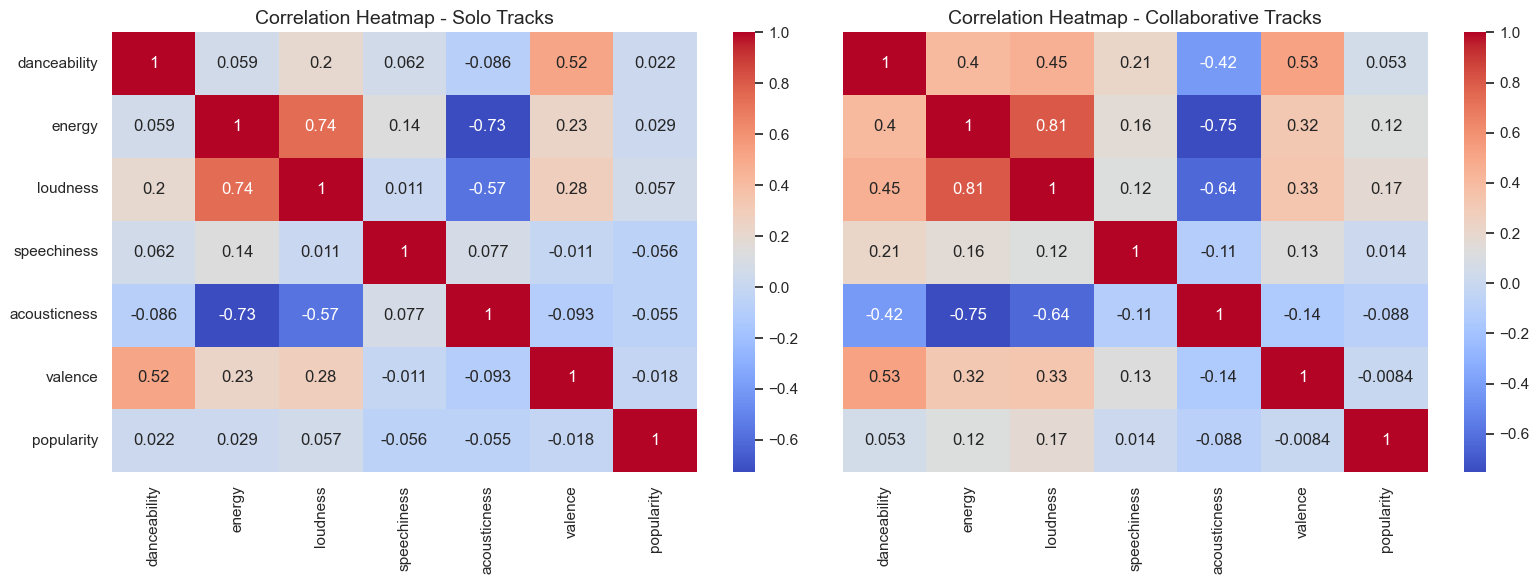

In [63]:
solo_corr = data[data['is_collaborative'] == False][['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'valence', 'popularity']].corr()
##
collab_corr = data[data['is_collaborative'] == True][['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'valence', 'popularity']].corr()
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
# Heatmap for Solo
sns.heatmap(solo_corr, annot=True, cmap='coolwarm', ax=axes[0])
axes[0].set_title('Correlation Heatmap - Solo Tracks', fontsize=14)

# Heatmap for Collab
sns.heatmap(collab_corr, annot=True, cmap='coolwarm', ax=axes[1])
axes[1].set_title('Correlation Heatmap - Collaborative Tracks', fontsize=14)

plt.tight_layout()
plt.show()



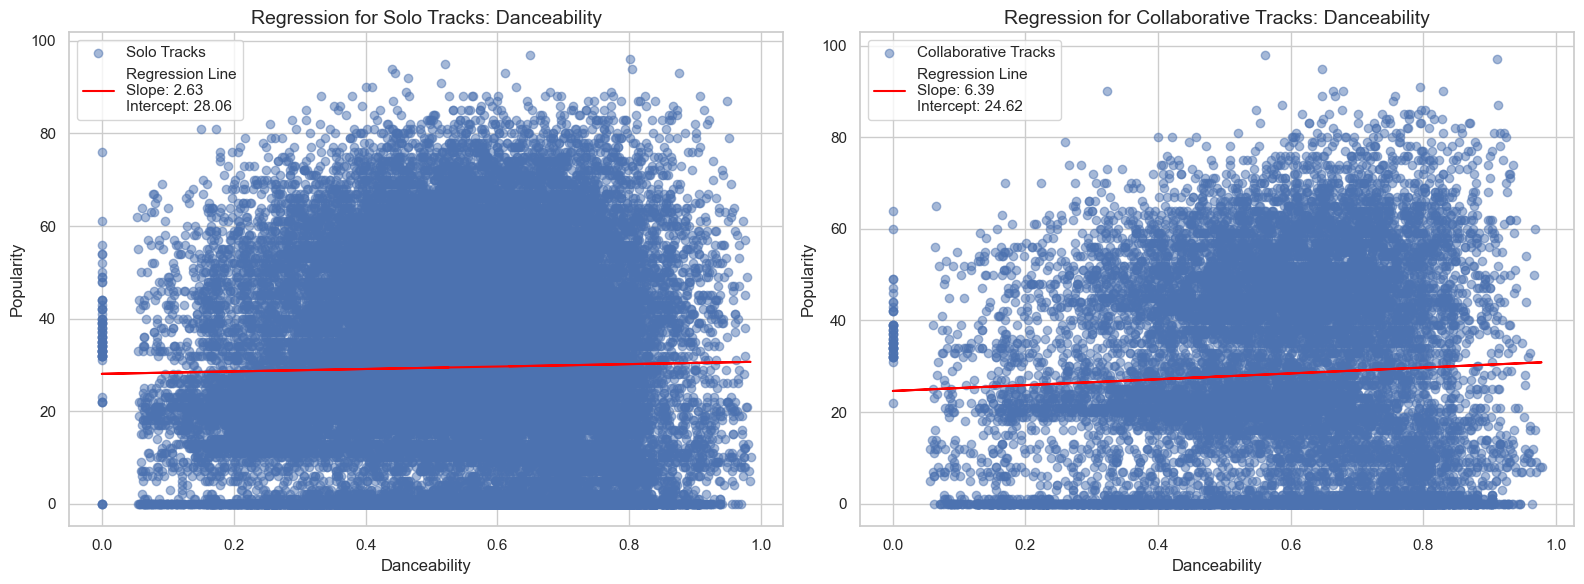

Regression Summary for Danceability (Solo Tracks):
Slope: 2.63
Intercept: 28.06

Regression Summary for Danceability (Collaborative Tracks):
Slope: 6.39
Intercept: 24.62


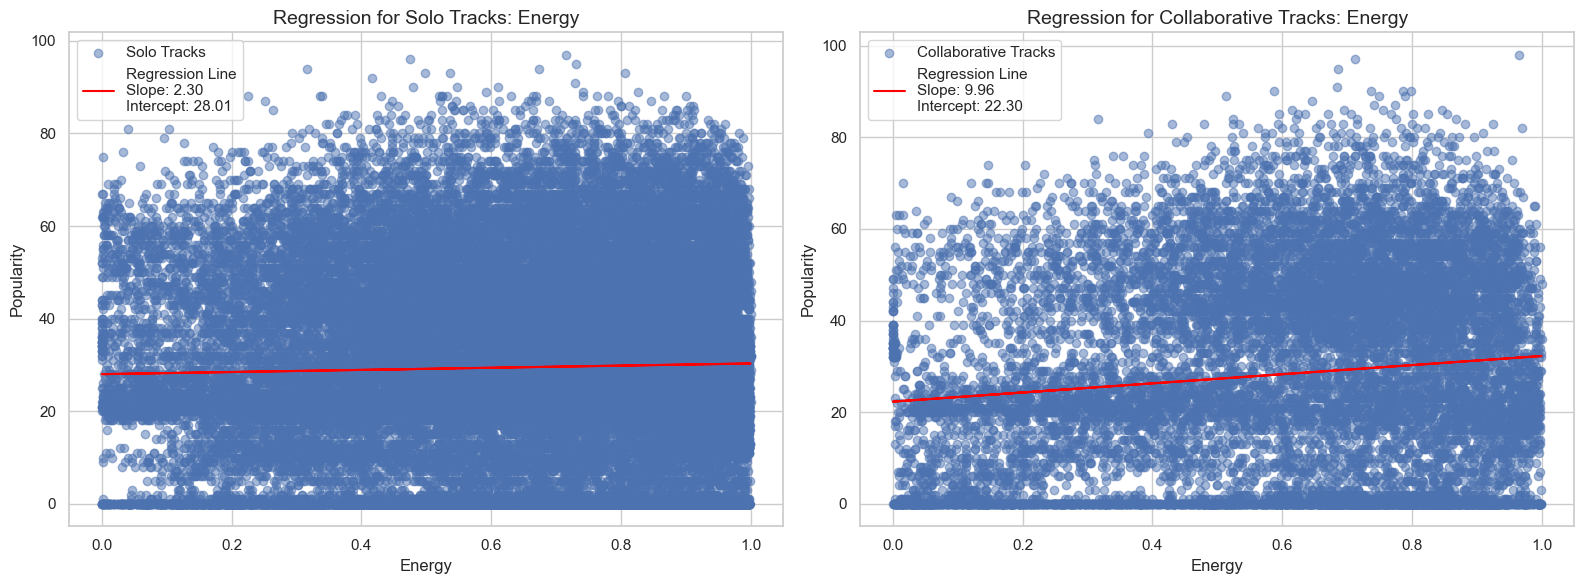

Regression Summary for Energy (Solo Tracks):
Slope: 2.30
Intercept: 28.01

Regression Summary for Energy (Collaborative Tracks):
Slope: 9.96
Intercept: 22.30


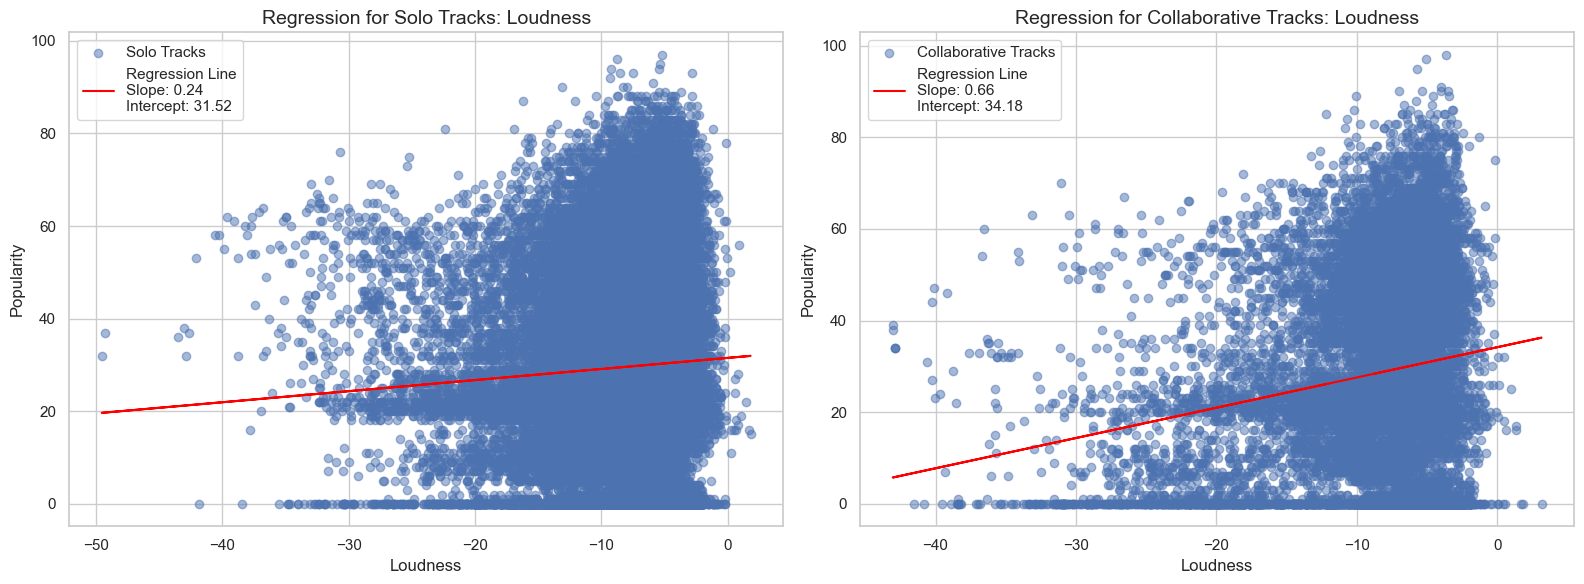

Regression Summary for Loudness (Solo Tracks):
Slope: 0.24
Intercept: 31.52

Regression Summary for Loudness (Collaborative Tracks):
Slope: 0.66
Intercept: 34.18


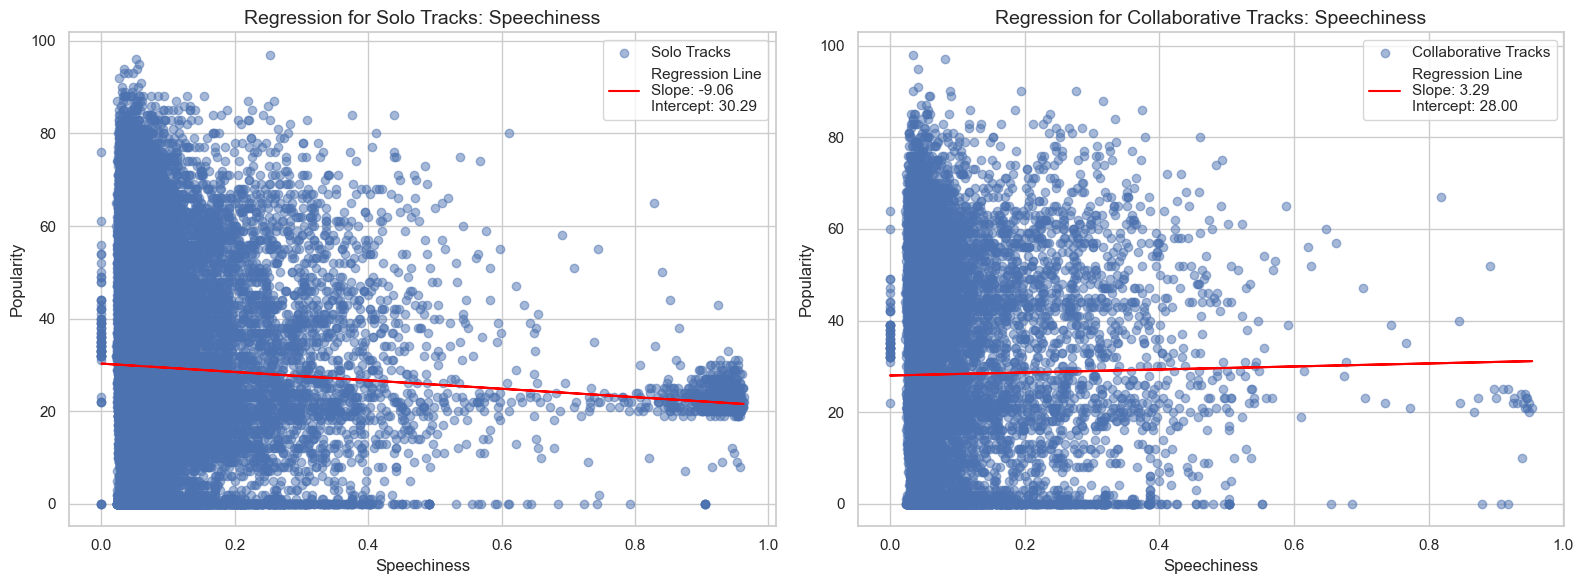

Regression Summary for Speechiness (Solo Tracks):
Slope: -9.06
Intercept: 30.29

Regression Summary for Speechiness (Collaborative Tracks):
Slope: 3.29
Intercept: 28.00


In [ ]:
#List of features that are varing much in solo and collaborative.
target = 'popularity'
for feature in ['danceability', 'energy', 'loudness', 'speechiness']:
    plt.figure(figsize=(16, 6))

    # Solo tracks regression
    solo_X = solo_tracks[feature].values.reshape(-1, 1)
    solo_y = solo_tracks[target].values
    solo_model = LinearRegression()
    solo_model.fit(solo_X, solo_y)
    solo_y_pred = solo_model.predict(solo_X)

    plt.subplot(1, 2, 1)
    plt.scatter(solo_X, solo_y, alpha=0.5, label="Solo Tracks")
    plt.plot(solo_X, solo_y_pred, color='red', label=f"Regression Line\nSlope: {solo_model.coef_[0]:.2f}\nIntercept: {solo_model.intercept_:.2f}")
    plt.title(f"Regression for Solo Tracks: {feature.capitalize()}", fontsize=14)
    plt.xlabel(feature.capitalize(), fontsize=12)
    plt.ylabel(target.capitalize(), fontsize=12)
    plt.legend()

    
    collab_X = collaborative_tracks[feature].values.reshape(-1, 1)
    collab_y = collaborative_tracks[target].values
    collab_model = LinearRegression()
    collab_model.fit(collab_X, collab_y)
    collab_y_pred = collab_model.predict(collab_X)

    plt.subplot(1, 2, 2)
    plt.scatter(collab_X, collab_y, alpha=0.5, label="Collaborative Tracks")
    plt.plot(collab_X, collab_y_pred, color='red', label=f"Regression Line\nSlope: {collab_model.coef_[0]:.2f}\nIntercept: {collab_model.intercept_:.2f}")
    plt.title(f"Regression for Collaborative Tracks: {feature.capitalize()}", fontsize=14)
    plt.xlabel(feature.capitalize(), fontsize=12)
    plt.ylabel(target.capitalize(), fontsize=12)
    plt.legend()

    plt.tight_layout()
    plt.show()


    print(f"\nRegression Summary for {feature.capitalize()} (Solo Tracks):")
    print(f"Slope: {solo_model.coef_[0]:.2f}")
    print(f"Intercept: {solo_model.intercept_:.2f}")

    print(f"\nRegression Summary for {feature.capitalize()} (Collaborative Tracks):")
    print(f"Slope: {collab_model.coef_[0]:.2f}")
    print(f"Intercept: {collab_model.intercept_:.2f}")


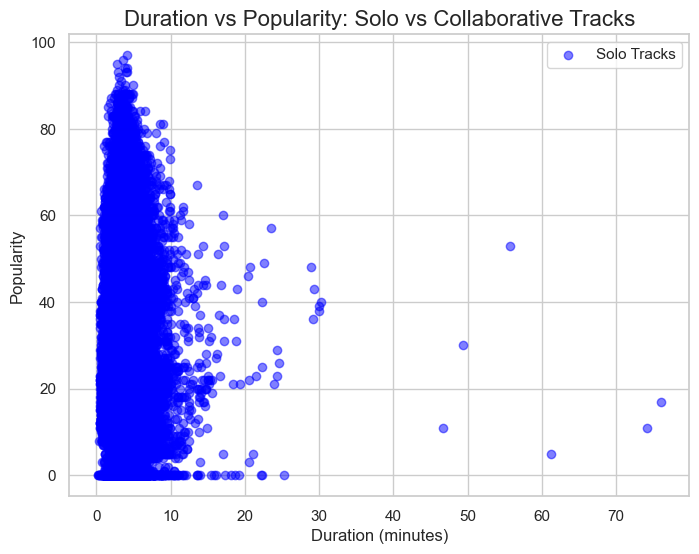

In [66]:
plt.figure(figsize=(8, 6))
plt.scatter(solo_tracks['duration_minutes'], solo_tracks['popularity'], alpha=0.5, label='Solo Tracks', color='blue')
plt.title('Duration vs Popularity: Solo vs Collaborative Tracks', fontsize=16)
plt.xlabel('Duration (minutes)', fontsize=12)
plt.ylabel('Popularity', fontsize=12)

plt.legend()
plt.show()

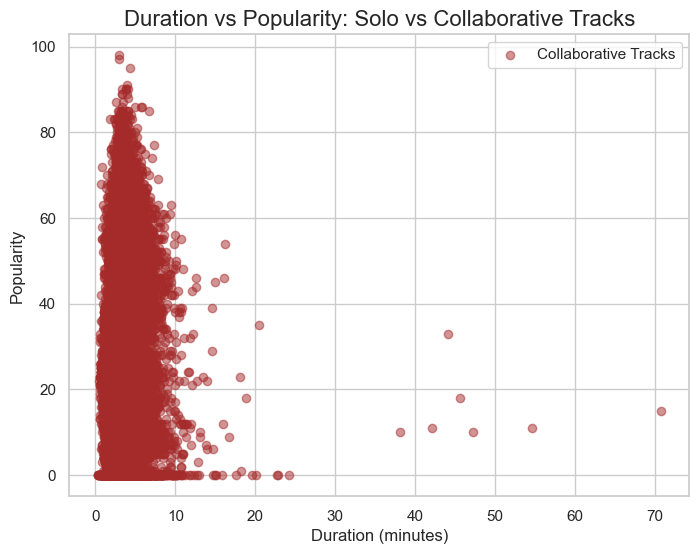

In [67]:
plt.figure(figsize=(8, 6))
plt.scatter(collaborative_tracks['duration_minutes'], collaborative_tracks['popularity'], alpha=0.5, label='Collaborative Tracks', color='brown')
plt.title('Duration vs Popularity: Solo vs Collaborative Tracks', fontsize=16)
plt.xlabel('Duration (minutes)', fontsize=12)
plt.ylabel('Popularity', fontsize=12)
plt.legend()

plt.show()